<a href="https://colab.research.google.com/github/alexmordashov/image_processing/blob/main/%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0%20%E2%84%965/%D0%9F%D1%80%D0%BE%D0%B5%D0%BA%D1%82%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%964_%D0%90%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7_%D0%B4%D0%B8%D0%BD%D0%B0%D0%BC%D0%B8%D0%BA%D0%B8_%D0%B8%D0%B7%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B9_%D0%B7%D0%B5%D0%BC%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BF%D0%BE%D0%BA%D1%80%D0%BE%D0%B2%D0%B0_%D0%BD%D0%B0_%D0%BF%D0%BE%D1%81%D0%BB%D0%B5%D0%B4%D0%BE%D0%B2%D0%B0%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D0%B8_%D1%80%D0%B0%D0%B7%D0%BD%D0%BE%D0%B2%D1%80%D0%B5%D0%BC%D0%B5%D0%BD%D0%BD%D1%8B%D1%85_%D1%81%D0%BD%D0%B8%D0%BC%D0%BA%D0%BE%D0%B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Проектная работа №4. Анализ динамики изменений земного покрова на последовательности разновременных спутниковых смимков с использованием спектральных индексов**

## **1. Цель работы**

Выполнить количественный анализ динамики изменения классов земного покрова на выбранной территории за период с 2017 по 2024 год на основе разновременных спутниковых снимков Sentinel-2 и провести сравнительную оценку результатов, полученных методом пороговой сегментации на основе спектральных индексов и с использованием готовых карт классификации Dynamic World.

## **2. Задачи работы**

1.  **Подготовить** последовательность разновременных снимков (снимки Sentinel-2 и карты Dynamic World) за 2017-2024 гг.;
2.  **Классифицировать** земной покров на снимках Sentinel-2, применив метод пороговой сегментации по спектральным индексам;
3.  **Рассчитать и сравнить** количественные показатели динамики (площади, темпы роста) для двух методов классификации: по индексам и по данным Dynamic World;
4.  **Оценить** выявленные тренды изменения покрова и **сформулировать** выводы о сопоставимости результатов двух методов анализа.

## **3. Загрузка данных для анализа из Google Earth Engine**

> **Примечание.** В качестве примера реализации можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/nWdJIg. Для выполнения текущей работы актуальны только **Раздел 1** и **Раздел 2** указанного источника.





### **3.1. Настройка рабочей среды и аутентификация**

In [ ]:
%%capture
!pip install -U geemap geedim rasterio scikit-learn scikit-image folium

In [ ]:
import ee
import geemap
import numpy as np
import pandas as pd
from datetime import datetime
import json
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import rasterio.plot
import cv2
import os
import pandas as pd

In [ ]:
ee.Authenticate()
ee.Initialize(project='project2ana')

### **3.2. Определение области интереса**

- Выберите территорию размером не менее 10×10 км (100 км²) с разнообразным земным покровом
- Обязательно должны присутствовать: водные объекты, растительность, застройка, открытая почва
- Зафиксируйте координаты углов ROI для воспроизводимости результатов

In [ ]:
roi_coords = [
    [40.84273, 57.81155],
    [41.01107, 57.81155],
    [41.01107, 57.72145],
    [40.84273, 57.72145],
    [40.84273, 57.81155]
]
roi = ee.Geometry.Polygon(roi_coords)
map_roi = geemap.Map(zoom=10)
map_roi.add_basemap('Esri.WorldTopoMap')
map_roi.centerObject(roi, 11)
map_roi.addLayer(roi, {'color': 'red'}, 'Область интереса')
map_roi

Map(center=[57.766509168167055, 40.92689999999903], controls=(WidgetControl(options=['position', 'transparent_…

### **3.3. Функции для загрузки и обработки данных Sentinel-2**

In [ ]:
def load_sentinel2_collection(roi, start_date, end_date, cloud_percentage=20):
    collection = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    collection = collection.filterBounds(roi)
    collection = collection.filterDate(start_date, end_date)
    collection = collection.filter(ee.Filter.lessThan('CLOUDY_PIXEL_PERCENTAGE', cloud_percentage))

    def mask_clouds(image):
        qa = image.select('QA60')
        cloud_bit_mask = 1 << 10
        cirrus_bit_mask = 1 << 11
        mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(qa.bitwiseAnd(cirrus_bit_mask).eq(0))

        return image.updateMask(mask).divide(10000).copyProperties(image, ['system:time_start'])

    return collection.map(mask_clouds)

### **3.4. Создание медианных композитов за летние периоды 2019-2024**

- Используйте медиану для минимизации влияния облачности
- Фильтрация по облачности: CLOUDY_PIXEL_PERCENTAGE < 20%


In [ ]:
def create_median_composite(collection, roi):
    median_image = collection.median()
    median_image = median_image.clip(roi)

    return median_image

In [ ]:
start_date = '2019-06-01'
end_date = '2019-08-31'
sentinel_2019 = create_median_composite(load_sentinel2_collection(roi, start_date, end_date), roi)

start_date = '2020-06-01'
end_date = '2020-08-31'
sentinel_2020 = create_median_composite(load_sentinel2_collection(roi, start_date, end_date), roi)

start_date = '2021-06-01'
end_date = '2021-08-31'
sentinel_2021 = create_median_composite(load_sentinel2_collection(roi, start_date, end_date), roi)

start_date = '2022-06-01'
end_date = '2022-08-31'
sentinel_2022 = create_median_composite(load_sentinel2_collection(roi, start_date, end_date), roi)

start_date = '2023-06-01'
end_date = '2023-08-31'
sentinel_2023 = create_median_composite(load_sentinel2_collection(roi, start_date, end_date), roi)

start_date = '2024-06-01'
end_date = '2024-08-31'
sentinel_2024 = create_median_composite(load_sentinel2_collection(roi, start_date, end_date), roi)

In [ ]:
vis_params = {'bands': ['B4', 'B3', 'B2'], 'min': 0.0, 'max': 0.3, 'gamma': 1.4}

map_composite = geemap.Map()
map_composite.add_basemap('Esri.WorldTopoMap')
map_composite.centerObject(roi, 11)
map_composite.addLayer(sentinel_2024, vis_params, 'Медианный композит RGB')

map_composite

Map(center=[57.766509168167055, 40.92689999999903], controls=(WidgetControl(options=['position', 'transparent_…

### **3.5. Функции для загрузки и обработки данных карт классификации**

**Используйте коллекцию Dynamic World (Google/WRI)**

**Коллекция в GEE:** `ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")`
- **Период:** с июня 2015 года по настоящее время (обновляется постоянно)
- **Разрешение:** 10 метров
- **Особенности:**
  - Предоставляет вероятности для каждого класса (не жесткую классификацию)
  - Обновляется почти в реальном времени для каждого снимка Sentinel-2
  - 9 классов земного покрова


```python
# Пример загрузки Dynamic World

def load_landcover_data(roi, start_date, end_date, composite='mode'):
    """
    Загружает карты классификации Google Dynamic World (10м).
    
    Классы: 0-Вода, 1-Деревья, 2-Трава, 3-Затопл.растительность,
            4-Культуры, 5-Кустарники, 6-Застройка, 7-Голая земля, 8-Снег/лед
    
    Args:
        roi: область интереса
        start_date, end_date: период 'YYYY-MM-DD'
        composite: 'mode'|'first'|'mosaic'|'collection'
    """
    
    labels = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1") \
        .filterBounds(roi) \
        .filterDate(start_date, end_date) \
        .select('label')
    
    if composite == 'collection':
        return labels.map(lambda img: img.clip(roi))
    
    return getattr(labels, composite)().clip(roi)

# Загрузка с композитом по моде (наиболее частый класс)
landcover = load_landcover_data(roi, '2024-06-01', '2024-08-31')

# Параметры визуализации для Dynamic World
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': [
        '419bdf',  # 0 - Вода - синий
        '397d49',  # 1 - Деревья - темно-зеленый  
        '88b053',  # 2 - Трава - светло-зеленый
        '7a87c6',  # 3 - Затопленная растительность - сине-фиолетовый
        'e49635',  # 4 - Культуры - оранжево-желтый
        'dfc35a',  # 5 - Кустарники - песочный
        'c4281b',  # 6 - Застройка - красный
        'a59b8f',  # 7 - Голая земля - серо-коричневый
        'b39fe1'   # 8 - Снег и лед - светло-фиолетовый (для контраста)
    ]
}

# Визуализация на карте
map_dw = geemap.Map()
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover, landcover_vis, 'Dynamic World')
map_dw

```

In [ ]:
def load_landcover_data(roi, start_date, end_date, composite='mode'):
    labels = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1") \
        .filterBounds(roi) \
        .filterDate(start_date, end_date) \
        .select('label')

    if composite == 'collection':
        return labels.map(lambda img: img.clip(roi))

    return getattr(labels, composite)().clip(roi)

### **3.4. Создание медианных карт классификации за летние периоды 2019-2024**

In [ ]:
landcover_2019 = load_landcover_data(roi, '2019-06-01', '2019-08-31')
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': ['419bdf', '397d49', '88b053', '7a87c6', 'e49635', 'dfc35a', 'c4281b', 'a59b8f', 'b39fe1']
}

map_dw = geemap.Map()
map_dw.add_basemap('Esri.WorldTopoMap')
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover_2019, landcover_vis, 'Dynamic World')
map_dw

Map(center=[57.766509168167055, 40.92689999999903], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
landcover_2020 = load_landcover_data(roi, '2020-06-01', '2020-08-31')
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': ['419bdf', '397d49', '88b053', '7a87c6', 'e49635', 'dfc35a', 'c4281b', 'a59b8f', 'b39fe1']
}

map_dw = geemap.Map()
map_dw.add_basemap('Esri.WorldTopoMap')
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover_2020, landcover_vis, 'Dynamic World')
map_dw

Map(center=[57.766509168167055, 40.92689999999903], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
landcover_2021 = load_landcover_data(roi, '2021-06-01', '2021-08-31')
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': ['419bdf', '397d49', '88b053', '7a87c6', 'e49635', 'dfc35a', 'c4281b', 'a59b8f', 'b39fe1']
}

map_dw = geemap.Map()
map_dw.add_basemap('Esri.WorldTopoMap')
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover_2021, landcover_vis, 'Dynamic World')
map_dw

Map(center=[57.76650916816746, 40.92690000000133], controls=(WidgetControl(options=['position', 'transparent_b…

In [ ]:
landcover_2022 = load_landcover_data(roi, '2022-06-01', '2022-08-31')
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': ['419bdf', '397d49', '88b053', '7a87c6', 'e49635', 'dfc35a', 'c4281b', 'a59b8f', 'b39fe1']
}

map_dw = geemap.Map()
map_dw.add_basemap('Esri.WorldTopoMap')
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover_2022, landcover_vis, 'Dynamic World')
map_dw

Map(center=[57.766509168167055, 40.92689999999903], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
landcover_2023 = load_landcover_data(roi, '2023-06-01', '2023-08-31')
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': ['419bdf', '397d49', '88b053', '7a87c6', 'e49635', 'dfc35a', 'c4281b', 'a59b8f', 'b39fe1']
}

map_dw = geemap.Map()
map_dw.add_basemap('Esri.WorldTopoMap')
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover_2023, landcover_vis, 'Dynamic World')
map_dw

Map(center=[57.76650916816746, 40.92690000000133], controls=(WidgetControl(options=['position', 'transparent_b…

In [ ]:
landcover_2024 = load_landcover_data(roi, '2024-06-01', '2024-08-31')
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': ['419bdf', '397d49', '88b053', '7a87c6', 'e49635', 'dfc35a', 'c4281b', 'a59b8f', 'b39fe1']
}

map_dw = geemap.Map()
map_dw.add_basemap('Esri.WorldTopoMap')
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover_2024, landcover_vis, 'Dynamic World')
map_dw

Map(center=[57.76650916816746, 40.92690000000133], controls=(WidgetControl(options=['position', 'transparent_b…

### **3.5. Экспорт полученных растров**

- **Медианные композиты** Sentinel-2 (7 файлов GeoTIFF):
  - `sentinel2_summer_2017.tif` (июнь-август 2017)
  - `sentinel2_summer_2018.tif` (июнь-август 2018)
  - `sentinel2_summer_2019.tif` (июнь-август 2019)
  - `sentinel2_summer_2020.tif` (июнь-август 2020)
  - `sentinel2_summer_2021.tif` (июнь-август 2021)
  - `sentinel2_summer_2022.tif` (июнь-август 2022)
  - `sentinel2_summer_2023.tif` (июнь-август 2023)
  - `sentinel2_summer_2024.tif` (июнь-август 2024)

- **Медианные карты классификации** (7 файлов GeoTIFF):
  - `DYNAMICWORLD_summer_2017.tif` (июнь-август 2017)
  - `DYNAMICWORLD_summer_2018.tif` (июнь-август 2018)
  - `DYNAMICWORLD_summer_2019.tif` (июнь-август 2019)
  - `DYNAMICWORLD_summer_2020.tif` (июнь-август 2020)
  - `DYNAMICWORLD_summer_2021.tif` (июнь-август 2021)
  - `DYNAMICWORLD_summer_2022.tif` (июнь-август 2022)
  - `DYNAMICWORLD_summer_2023.tif` (июнь-август 2023)
  - `DYNAMICWORLD_summer_2024.tif` (июнь-август 2024)

In [ ]:
def export_georeferenced_raster(image, roi, filename, scale=10):
    geemap.download_ee_image(image=image, filename=filename, scale=scale, region=roi, crs='EPSG:4326')

    print(f"Растр сохранен: {filename}")
    return filename

In [ ]:
export_georeferenced_raster(sentinel_2019, roi, "sentinel2_summer_2019.tif", scale=10)
export_georeferenced_raster(sentinel_2020, roi, "sentinel2_summer_2020.tif", scale=10)
export_georeferenced_raster(sentinel_2021, roi, "sentinel2_summer_2021.tif", scale=10)
export_georeferenced_raster(sentinel_2022, roi, "sentinel2_summer_2022.tif", scale=10)
export_georeferenced_raster(sentinel_2023, roi, "sentinel2_summer_2023.tif", scale=10)
export_georeferenced_raster(sentinel_2024, roi, "sentinel2_summer_2024.tif", scale=10)

export_georeferenced_raster(landcover_2019, roi, "DYNAMICWORLD_summer_2019.tif", scale=10)
export_georeferenced_raster(landcover_2020, roi, "DYNAMICWORLD_summer_2020.tif", scale=10)
export_georeferenced_raster(landcover_2021, roi, "DYNAMICWORLD_summer_2021.tif", scale=10)
export_georeferenced_raster(landcover_2022, roi, "DYNAMICWORLD_summer_2022.tif", scale=10)
export_georeferenced_raster(landcover_2023, roi, "DYNAMICWORLD_summer_2023.tif", scale=10)
export_georeferenced_raster(landcover_2024, roi, "DYNAMICWORLD_summer_2024.tif", scale=10)

  0%|          |0/52 tiles [00:00<?]

Растр сохранен: sentinel2_summer_2019.tif


  0%|          |0/52 tiles [00:00<?]

Растр сохранен: sentinel2_summer_2020.tif


  0%|          |0/52 tiles [00:00<?]

...

  0%|          |0/1 tiles [00:00<?]

Растр сохранен: DYNAMICWORLD_summer_2023.tif


  0%|          |0/1 tiles [00:00<?]

Растр сохранен: DYNAMICWORLD_summer_2024.tif


'DYNAMICWORLD_summer_2024.tif'

## **4. Работа с загруженными растрами в RasterIO**

### **4.1. Загрузка и проверка растров**

In [ ]:
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm

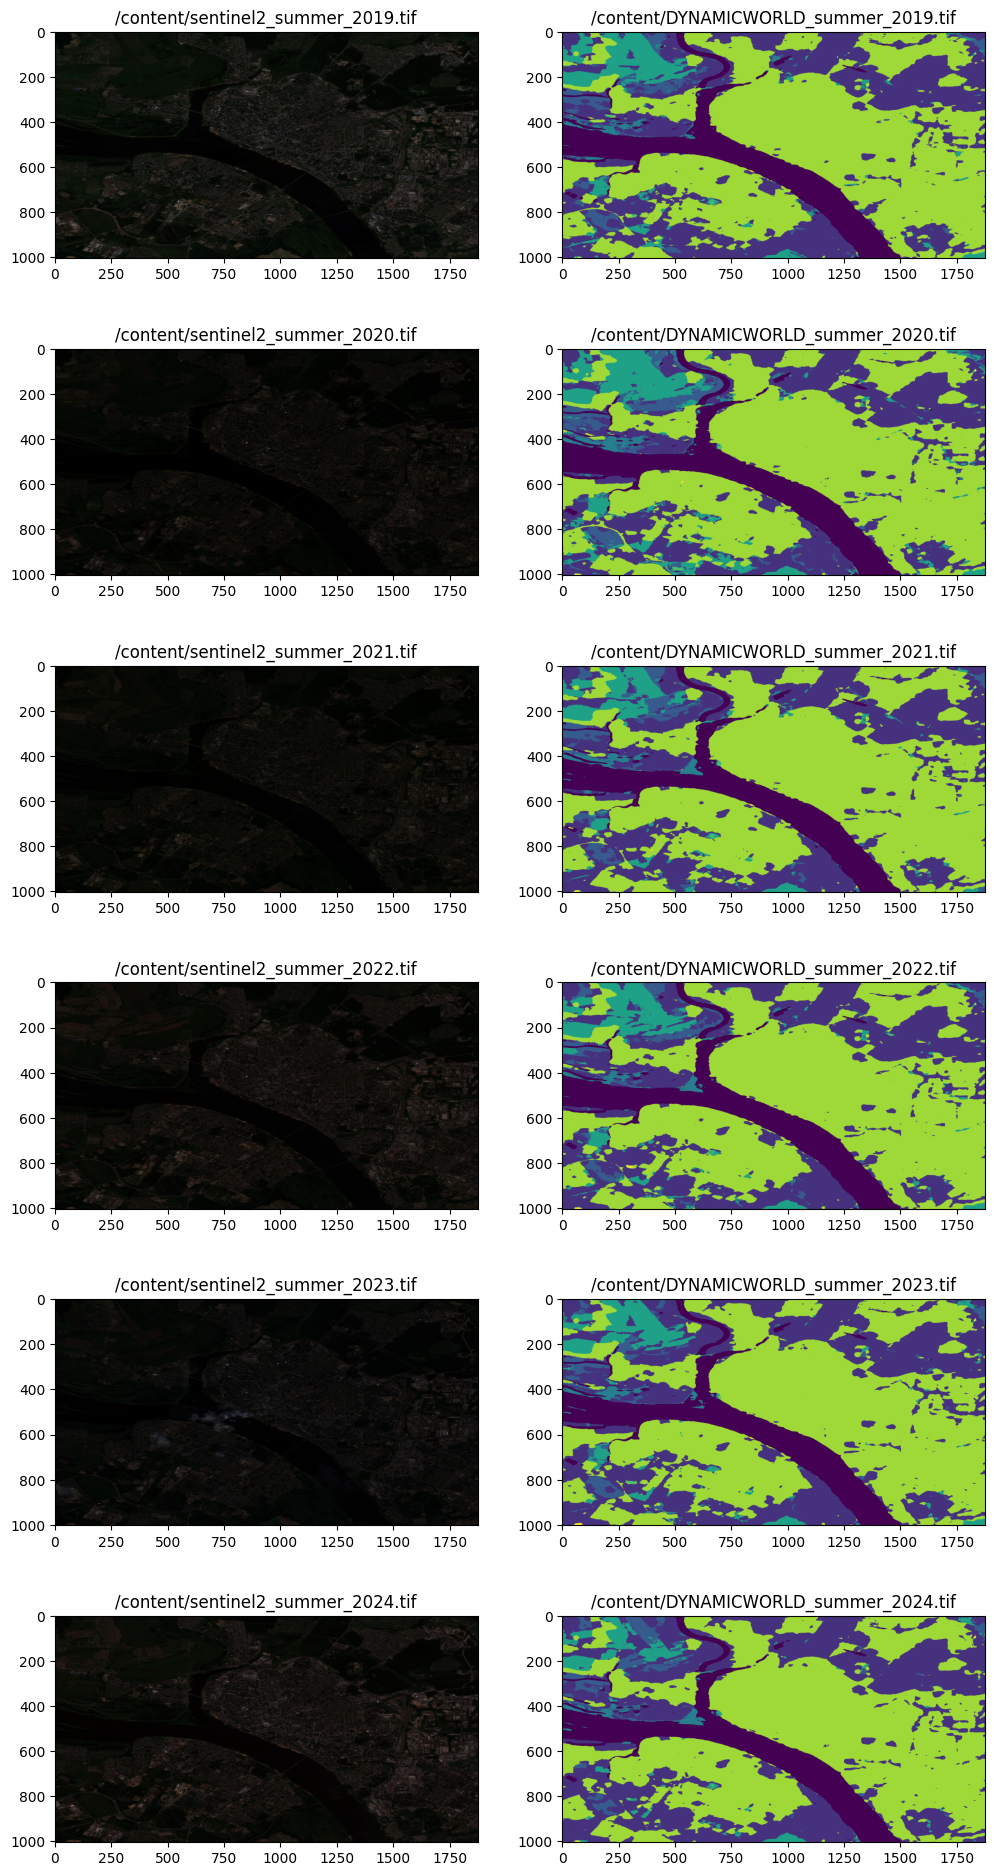

In [ ]:
sentinel_list = [
    "/content/sentinel2_summer_2019.tif",
    "/content/sentinel2_summer_2020.tif",
    "/content/sentinel2_summer_2021.tif",
    "/content/sentinel2_summer_2022.tif",
    "/content/sentinel2_summer_2023.tif",
    "/content/sentinel2_summer_2024.tif"
]
dynamic_list = [
    "/content/DYNAMICWORLD_summer_2019.tif",
    "/content/DYNAMICWORLD_summer_2020.tif",
    "/content/DYNAMICWORLD_summer_2021.tif",
    "/content/DYNAMICWORLD_summer_2022.tif",
    "/content/DYNAMICWORLD_summer_2023.tif",
    "/content/DYNAMICWORLD_summer_2024.tif"
]
count = 1

plt.figure(figsize=(12, 24))
for i in range(len(sentinel_list)):
    sentinel_tile = rasterio.open(sentinel_list[i])
    rgb_image = np.dstack((normalize(sentinel_tile.read(4)), normalize(sentinel_tile.read(3)), normalize(sentinel_tile.read(2))))

    plt.subplot(len(sentinel_list), 2, count)
    plt.imshow(rgb_image)
    plt.title(sentinel_list[i])
    count += 1

    dynamic_tile = rasterio.open(dynamic_list[i]).read(1)
    plt.subplot(len(sentinel_list), 2, count)
    plt.imshow(dynamic_tile)
    plt.title(dynamic_list[i])
    count += 1

plt.show()

In [ ]:
# Ваш код (Выведите на графиках все карты классификаций)

### **4.2. Рассчитать все 8 индексов для каждого года (2015-2024)**


> **Примечание.** В качестве примера рассчета индексов можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/4qBeIg





**Спектральные индексы** — это математические комбинации значений отражения в разных спектральных каналах, позволяющие выделить определенные типы объектов.








#### **Таблица 1. Основные спектральные индексы для анализа земного покрова**




| **Индекс** | **Формула** | **Назначение** | **Каналы Sentinel-2** |
|------------|-------------|----------------|------------------------|
| **NDVI** (Normalized Difference Vegetation Index) | (NIR - RED) / (NIR + RED) | Оценка состояния растительности | (B8 - B4) / (B8 + B4) |
| **NDWI** (Normalized Difference Water Index) | (GREEN - NIR) / (GREEN + NIR) | Выделение водных объектов | (B3 - B8) / (B3 + B8) |
| **NDBI** (Normalized Difference Built-up Index) | (SWIR - NIR) / (SWIR + NIR) | Выделение застроенных территорий | (B11 - B8) / (B11 + B8) |
| **SAVI** (Soil Adjusted Vegetation Index) | ((NIR - RED) / (NIR + RED + L)) * (1 + L), L=0.5 | Растительность с учетом почвы | ((B8 - B4) / (B8 + B4 + 0.5)) * 1.5 |
| **EVI** (Enhanced Vegetation Index) | 2.5 * ((NIR - RED) / (NIR + 6*RED - 7.5*BLUE + 1)) | Улучшенный вегетационный индекс | 2.5 * ((B8 - B4) / (B8 + 6*B4 - 7.5*B2 + 1)) |
| **MNDWI** (Modified NDWI) | (GREEN - SWIR) / (GREEN + SWIR) | Модифицированный водный индекс | (B3 - B11) / (B3 + B11) |
| **BSI** (Bare Soil Index) | ((SWIR + RED) - (NIR + BLUE)) / ((SWIR + RED) + (NIR + BLUE)) | Открытая почва | ((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2)) |
| **NDSI** (Normalized Difference Snow Index) | (GREEN - SWIR) / (GREEN + SWIR) | Снежный покров | (B3 - B11) / (B3 + B11) |


#### **Таблица 2. Интерпретация значений NDVI**



| **Диапазон NDVI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| < 0.0 | Вода | Водные поверхности, снег |
| 0.0 - 0.1 | Открытая почва | Песок, камни, бетон |
| 0.1 - 0.2 | Разреженная растительность | Степи, пустыни |
| 0.2 - 0.4 | Умеренная растительность | Кустарники, луга |
| 0.4 - 0.6 | Плотная растительность | Лиственные леса |
| > 0.6 | Очень плотная растительность | Тропические леса, хвойные леса |

#### **Таблица 3. Интерпретация значений NDWI**



| **Диапазон NDWI** | **Тип объекта** | **Описание** |
|-------------------|-----------------|--------------|
| > 0.3 | Водные объекты | Реки, озера, пруды |
| 0.0 - 0.3 | Влажная почва/растительность | Болота, заливные луга |
| -0.3 - 0.0 | Сухая растительность | Обычная растительность |
| < -0.3 | Застройка/почва | Городская застройка, открытая почва |

#### **Таблица 4. Интерпретация значений NDBI**



| **Диапазон NDBI** | **Тип территории** | **Характеристика** |
|-------------------|-------------------|---------------------|
| > 0.0 | Застроенные территории | Города, промзоны |
| -0.1 - 0.0 | Смешанные территории | Пригороды, села |
| < -0.1 | Природные территории | Леса, поля, водоемы |

#### **Таблица 5. Интерпретация значений SAVI**



| **Диапазон SAVI** | **Тип покрова** | **Описание** |
|-------------------|-----------------|---------------|
| < 0.1 | Открытая почва/вода | Водные объекты, голая почва |
| 0.1 - 0.2 | Очень разреженная растительность | Пустыни, каменистые участки |
| 0.2 - 0.4 | Разреженная растительность | Степи, саванны |
| 0.4 - 0.6 | Умеренная растительность | Сельхозугодья, луга |
| > 0.6 | Плотная растительность | Леса, густые кустарники |

#### **Таблица 6. Интерпретация значений EVI**



| **Диапазон EVI** | **Состояние растительности** | **Характеристика** |
|------------------|------------------------------|---------------------|
| < 0.0 | Нет растительности | Вода, снег, облака |
| 0.0 - 0.2 | Минимальная растительность | Голая почва, урбанизированные территории |
| 0.2 - 0.3 | Низкая биомасса | Травянистая растительность |
| 0.3 - 0.5 | Средняя биомасса | Кустарники, молодые посевы |
| 0.5 - 0.8 | Высокая биомасса | Зрелые леса, интенсивное сельское хозяйство |
| > 0.8 | Очень высокая биомасса | Тропические леса |

#### **Таблица 7. Интерпретация значений MNDWI**



| **Диапазон MNDWI** | **Тип объекта** | **Характеристика** |
|--------------------|-----------------|---------------------|
| > 0.5 | Глубокая вода | Озера, моря, водохранилища |
| 0.2 - 0.5 | Мелкая вода | Реки, каналы, мелководья |
| 0.0 - 0.2 | Влажные территории | Болота, рисовые поля |
| < 0.0 | Суша | Растительность, почва, застройка |

#### **Таблица 8. Интерпретация значений BSI**



| **Диапазон BSI** | **Тип поверхности** | **Описание** |
|-------------------|-------------------|---------------|
| > 0.1 | Открытая почва | Пашни, карьеры, пустыни |
| 0.0 - 0.1 | Частично покрытая почва | Разреженная растительность |
| -0.1 - 0.0 | Смешанный покров | Переходные зоны |
| < -0.1 | Растительность/вода | Леса, водоемы, плотная растительность |

#### **Таблица 9. Интерпретация значений NDSI**



| **Диапазон NDSI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| > 0.4 | Снежный покров | Чистый снег, ледники |
| 0.2 - 0.4 | Частичный снежный покров | Смешанный снег с растительностью |
| 0.0 - 0.2 | Возможный снег/лед | Тающий снег, иней, облака |
| -0.2 - 0.0 | Переходная зона | Влажная почва, туман |
| < -0.2 | Бесснежные территории | Растительность, почва, вода |

In [ ]:
def calculate_indices(filename):
  data = rasterio.open(filename)

  prof = data.profile
  prof.update(dtype=rasterio.float32, count=1, compress="lzw")

  BLUE = data.read(2)
  GREEN = data.read(3)
  RED = data.read(4)
  NIR = data.read(8)
  SWIR = data.read(11)
  L = 0.5

  NDVI =	(NIR - RED) / (NIR + RED)
  NDVI = NDVI.clip(-1, 1)

  NDWI = (GREEN - NIR) / (GREEN + NIR)
  NDWI = NDWI.clip(-1, 1)

  NDBI = (SWIR - NIR) / (SWIR + NIR)
  NDBI = NDBI.clip(-1, 1)

  SAVI = ((NIR - RED) / (NIR + RED + L)) * (1 + L)
  SAVI = SAVI.clip(-1, 1)

  EVI =	2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1))
  EVI = EVI.clip(-1, 1)

  MNDWI =	(GREEN - SWIR) / (GREEN + SWIR)
  MNDWI = MNDWI.clip(-1, 1)

  BSI =	((SWIR + RED) - (NIR + BLUE)) / ((SWIR + RED) + (NIR + BLUE))
  BSI = BSI.clip(-1, 1)

  NDSI = (GREEN - SWIR) / (GREEN + SWIR)
  NDSI = NDSI.clip(-1, 1)

  return prof, NDVI, NDWI, NDBI, SAVI, EVI, MNDWI, BSI, NDSI

### **4.3. Визуализировать каждый индекс для 2024 года с соответствующей цветовой шкалой**



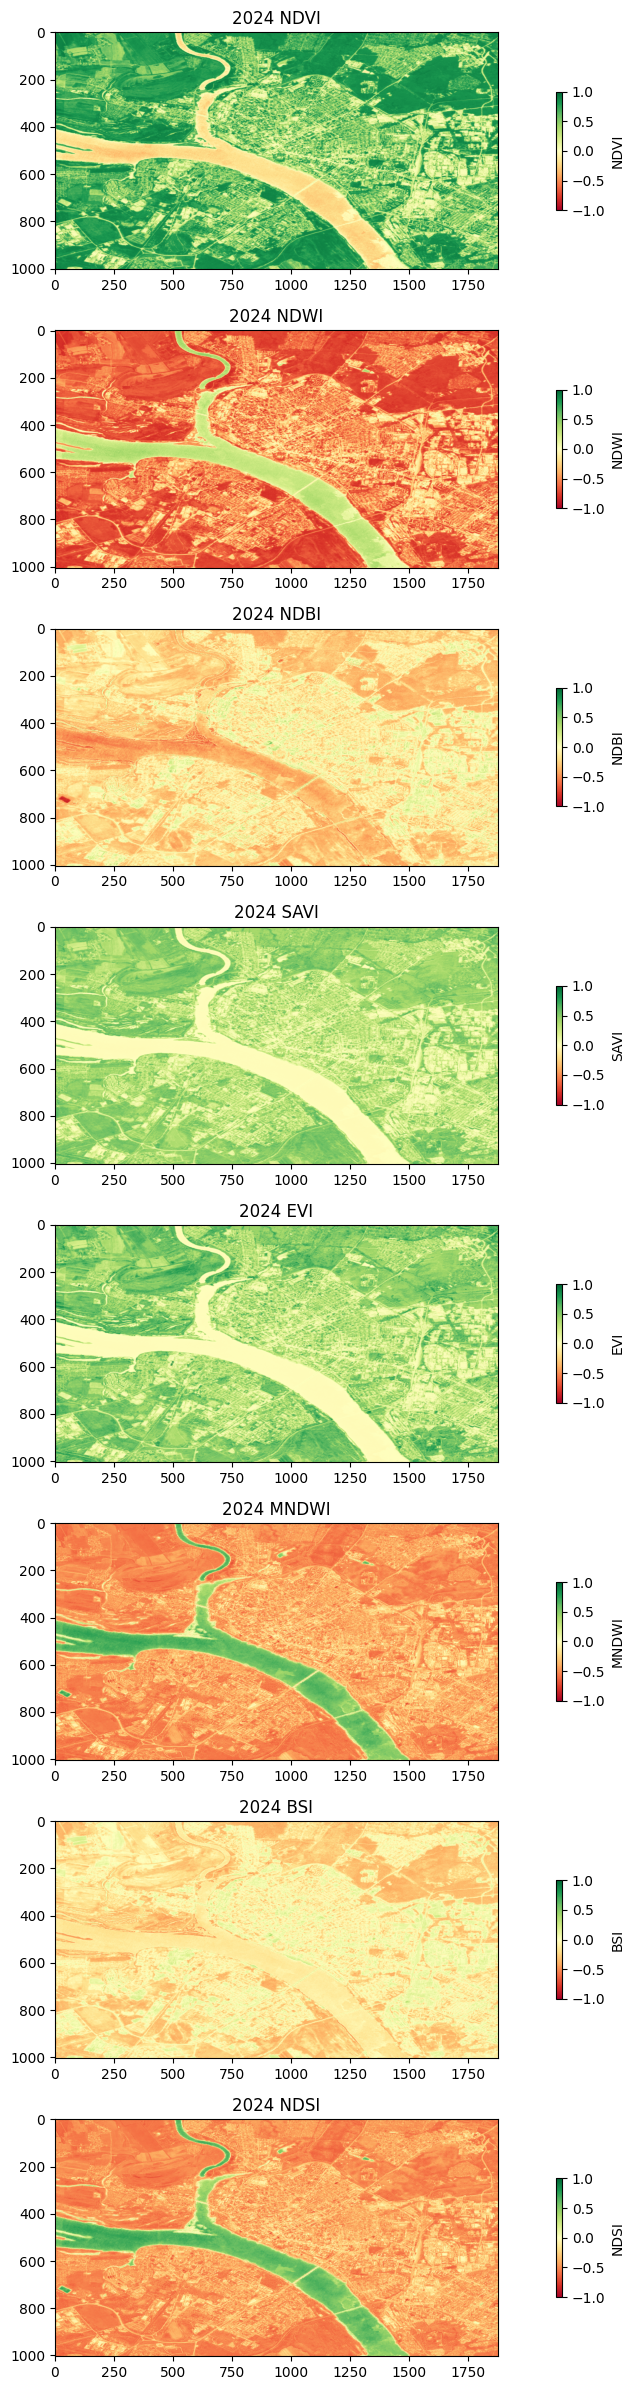

In [ ]:
profile, ndvi, ndwi, ndbi, savi, evi, mndwi, bsi, ndsi = calculate_indices("/content/sentinel2_summer_2024.tif")

plt.figure(figsize=(12, 24))

plt.subplot(8, 1, 1)
plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI", shrink=0.5)
plt.title("2024 NDVI")

plt.subplot(8, 1, 2)
plt.imshow(ndwi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDWI", shrink=0.5)
plt.title("2024 NDWI")

plt.subplot(8, 1, 3)
plt.imshow(ndbi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDBI", shrink=0.5)
plt.title("2024 NDBI")

plt.subplot(8, 1, 4)
plt.imshow(savi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="SAVI", shrink=0.5)
plt.title("2024 SAVI")

plt.subplot(8, 1, 5)
plt.imshow(evi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="EVI", shrink=0.5)
plt.title("2024 EVI")

plt.subplot(8, 1, 6)
plt.imshow(mndwi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="MNDWI", shrink=0.5)
plt.title("2024 MNDWI")

plt.subplot(8, 1, 7)
plt.imshow(bsi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="BSI", shrink=0.5)
plt.title("2024 BSI")

plt.subplot(8, 1, 8)
plt.imshow(ndsi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDSI", shrink=0.5)
plt.title("2024 NDSI")

plt.tight_layout()
plt.show()

### **4.4. Сохранить все рассчитанные индексы в отдельные GeoTIFF файлы с сохранением геопривязки (сохранить в соответствующие папки по годам)**



In [ ]:
sentinel_list = [
    "/content/sentinel2_summer_2019.tif",
    "/content/sentinel2_summer_2020.tif",
    "/content/sentinel2_summer_2021.tif",
    "/content/sentinel2_summer_2022.tif",
    "/content/sentinel2_summer_2023.tif",
    "/content/sentinel2_summer_2024.tif"
]

for i in sentinel_list:
  profile, ndvi, ndwi, ndbi, savi, evi, mndwi, bsi, ndsi = calculate_indices(i)

  name = i.split(".")[0].split("_")[2]
  os.mkdir(f"/content/{name}")
  with rasterio.open(f"/content/{name}/ndvi_{name}.tif", "w", **profile) as dst:
      dst.write(ndvi, 1)
  with rasterio.open(f"/content/{name}/ndwi_{name}.tif", "w", **profile) as dst:
      dst.write(ndwi, 1)
  with rasterio.open(f"/content/{name}/ndbi_{name}.tif", "w", **profile) as dst:
      dst.write(ndbi, 1)
  with rasterio.open(f"/content/{name}/savi_{name}.tif", "w", **profile) as dst:
      dst.write(savi, 1)
  with rasterio.open(f"/content/{name}/evi_{name}.tif", "w", **profile) as dst:
      dst.write(evi, 1)
  with rasterio.open(f"/content/{name}/mndwi_{name}.tif", "w", **profile) as dst:
      dst.write(mndwi, 1)
  with rasterio.open(f"/content/{name}/bsi_{name}.tif", "w", **profile) as dst:
      dst.write(bsi, 1)
  with rasterio.open(f"/content/{name}/ndsi_{name}.tif", "w", **profile) as dst:
      dst.write(ndsi, 1)

## **5. Сегментация и классификация**

**Сегментация** — процесс разделения изображения на однородные регионы (сегменты) на основе заданных критериев .


### **5.1. Многопороговая сегментация с использованием спектральных индексов**



**Задание:** Реализовать классификацию земного покрова путем замены значений пикселей в растрах индексов на метки классов согласно пороговым правилам.

**Пояснение:** По сути необходимо преобразовать непрерывные значения индексов в дискретные классы (метки) на основе пороговых значений из Таблиц 2-9. Каждому пикселю присваивается числовая метка класса (0-8) в зависимости от значений спектральных индексов.






**Алгоритм многопороговой сегментации:**
1. Создать пустой растр для меток классов (заполнить значением -1 или 255 для "неклассифицировано")
2. Последовательно применить правила классификации
3. Каждое правило проверяется только для еще не классифицированных пикселей
4. Присвоить соответствующую метку класса пикселям, удовлетворяющим условию

**Иерархия правил классификации (применять строго последовательно):**
1. **Вода (метка=0)**: (NDWI > 0.3) ИЛИ (MNDWI > 0.2)
2. **Снег/лед (метка=1)**: (NDSI > 0.4) И (еще не классифицировано)
3. **Застройка (метка=2)**: (NDBI > 0.0) И (NDVI < 0.2) И (еще не классифицировано)
4. **Густая растительность (метка=3)**: ((NDVI > 0.6) ИЛИ (EVI > 0.5)) И (еще не классифицировано)
5. **Умеренная растительность (метка=4)**: (0.3 ≤ NDVI ≤ 0.6) И (еще не классифицировано)
6. **Разреженная растительность (метка=5)**: (0.1 ≤ NDVI < 0.3) И (еще не классифицировано)
7. **Открытая почва (метка=6)**: (BSI > 0.0) И (NDVI < 0.1) И (еще не классифицировано)
8. **Прочее (метка=7)**: все оставшиеся неклассифицированные пиксели


**(МОЖЕТЕ СФОРМУЛИРОВАТЬ СВОИ ПРАВИЛА, ОСНОВЫВАЯСЬ НА ТАБЛИЦАХ, ПРИВЕДЕННЫХ ВЫШЕ!)**

In [ ]:
def segmentation(NDVI, NDWI, NDBI, SAVI, EVI, MNDWI, BSI, NDSI):
  segment_rastr = np.full_like(ndvi, -1, dtype=int)
  for i in range(len(segment_rastr)):
    for j in range(len(segment_rastr[i])):
      if NDWI[0][i][j] > 0.3 or MNDWI[0][i][j] > 0.2:
        segment_rastr[i][j] = 0
      elif NDSI[0][i][j] > 0.4 and segment_rastr[i][j] == -1:
        segment_rastr[i][j] = 1
      elif NDBI[0][i][j] > 0.0 and NDVI[0][i][j] < 0.2 and segment_rastr[i][j] == -1:
        segment_rastr[i][j] = 2
      elif (NDVI[0][i][j] > 0.6 or EVI[0][i][j] > 0.5) and segment_rastr[i][j] == -1:
        segment_rastr[i][j] = 3
      elif (0.3 <= NDVI[0][i][j] <= 0.6) and segment_rastr[i][j] == -1:
        segment_rastr[i][j] = 4
      elif (0.1 <= NDVI[0][i][j] < 0.3) and segment_rastr[i][j] == -1:
        segment_rastr[i][j] = 5
      elif BSI[0][i][j] > 0.0 and NDVI[0][i][j] < 0.1 and segment_rastr[i][j] == -1:
        segment_rastr[i][j] = 6
      else:
        segment_rastr[i][j] = 7
  return segment_rastr

ndvi_2024 = rasterio.open("/content/2024/ndvi_2024.tif").read()
ndwi_2024 = rasterio.open("/content/2024/ndwi_2024.tif").read()
ndbi_2024 = rasterio.open("/content/2024/ndbi_2024.tif").read()
savi_2024 = rasterio.open("/content/2024/savi_2024.tif").read()
evi_2024 = rasterio.open("/content/2024/evi_2024.tif").read()
mndwi_2024 = rasterio.open("/content/2024/mndwi_2024.tif").read()
bsi_2024 = rasterio.open("/content/2024/bsi_2024.tif").read()
ndsi_2024 = rasterio.open("/content/2024/ndsi_2024.tif").read()
result_of_seg = segmentation(ndvi_2024, ndwi_2024, ndbi_2024, savi_2024, evi_2024, mndwi_2024, bsi_2024, ndsi_2024)
print(result_of_seg)

[[3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 ...
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]]



### **5.2. Подсчет количества пикселей каждого класса**



**Задание:** После замены значений индексов на метки классов, подсчитать количество пикселей для каждой метки класса.

**Пояснение:** Используйте функции numpy.unique() или аналогичные для подсчета количества пикселей с каждой меткой. Это позволит получить статистику распределения классов на изображении.

**Что нужно получить:**
- Массив уникальных меток классов (0-7)
- Количество пикселей для каждой метки
- Процентное соотношение классов от общего числа пикселей

In [ ]:
unique_indices = np.unique(result_of_seg)
segment_dict = {}
count_of_pixels = 0
for i in unique_indices:
  segment_dict[int(i)] = np.count_nonzero(result_of_seg == i)
  count_of_pixels += np.count_nonzero(result_of_seg == i)

print(f"Массив уникальных меток классов (0-7)\n{unique_indices}\n")

print("Количество пикселей для каждой метки")
for key, value in segment_dict.items():
  print(f"{key}: {value}")

print("\nПроцентное соотношение классов от общего числа пикселей")
for key, value in segment_dict.items():
  print(f"{key}: {(value / count_of_pixels * 100):.2f}%")

Массив уникальных меток классов (0-7)
[0 2 3 4 5 6 7]

Количество пикселей для каждой метки
0: 176924
2: 140592
3: 965106
4: 447696
5: 137789
6: 8207
7: 6186

Процентное соотношение классов от общего числа пикселей
0: 9.40%
2: 7.47%
3: 51.27%
4: 23.78%
5: 7.32%
6: 0.44%
7: 0.33%


### **5.3. Применение сегментации ко всем временным срезам**




**Задание:** Применить разработанный алгоритм сегментации ко всем медианным композитам (2017-2024).

**Пояснение:** Использовать одинаковые пороговые значения для всех лет для обеспечения сопоставимости результатов при анализе динамики. Сохранить результаты сегментации как растры с метками классов.

**Выходные данные:**
- 8 растров с метками классов (по одному на каждый год)
- Таблица с количеством пикселей каждого класса для каждого года
- Формат сохранения: GeoTIFF с сохранением геопривязки

In [ ]:
segmented = {}
table_dict = {'Class': [0, 1, 2, 3, 4, 5, 6, 7], 2019: [], 2020: [], 2021: [], 2022: [], 2023: [], 2024: []}
for i in [2019, 2020, 2021, 2022, 2023, 2024]:
  ndvi_ = rasterio.open(f"/content/{i}/ndvi_{i}.tif")
  ndwi_ = rasterio.open(f"/content/{i}/ndwi_{i}.tif")
  ndbi_ = rasterio.open(f"/content/{i}/ndbi_{i}.tif")
  savi_ = rasterio.open(f"/content/{i}/savi_{i}.tif")
  evi_ = rasterio.open(f"/content/{i}/evi_{i}.tif")
  mndwi_ = rasterio.open(f"/content/{i}/mndwi_{i}.tif")
  bsi_ = rasterio.open(f"/content/{i}/bsi_{i}.tif")
  ndsi_ = rasterio.open(f"/content/{i}/ndsi_{i}.tif")
  result_of_seg = segmentation(ndvi_.read(), ndwi_.read(), ndbi_.read(), savi_.read(),
                             evi_.read(), mndwi_.read(), bsi_.read(), ndsi_.read())
  segmented[i] = result_of_seg
  profile = ndvi_.profile

  for j in table_dict['Class']:
    table_dict[i].append(str(np.count_nonzero(result_of_seg == j)))

  with rasterio.open(f"/content/{i}/segmentation_{i}.tif", "w", **profile) as dst:
      dst.write(result_of_seg, 1)

table_df = pd.DataFrame(table_dict)
display(table_df)

,Class,2019,2020,2021,2022,2023,2024
0,0,184074,177087,174502,175149,166553,176924
1,1,0,0,0,0,0,0
2,2,130204,149336,161970,153462,152948,140592
3,3,1009293,978898,938890,918079,941167,965106
4,4,418544,432395,454242,472589,448556,447696
5,5,131209,131808,141294,148432,158123,137789
6,6,4868,5386,5652,7260,7836,8207
7,7,4308,7590,5950,7529,7317,6186


### **5.4. Визуализация результатов сегментации**






**Задание:** Создать тематические карты классификации с легендой.

**Пояснение:** Назначить каждой метке класса соответствующий цвет для визуализации. Использовать стандартную цветовую схему для классов земного покрова.

**Цветовая схема для визуализации:**
- 0 - Вода: синий (#419bdf)
- 1 - Снег/лед: белый (#ffffff)  
- 2 - Застройка: красный (#c4281b)
- 3 - Густая растительность: темно-зеленый (#397d49)
- 4 - Умеренная растительность: зеленый (#88b053)
- 5 - Разреженная растительность: светло-зеленый (#7a87c6)
- 6 - Открытая почва: коричневый (#a59b8f)
- 7 - Прочее: серый (#808080)

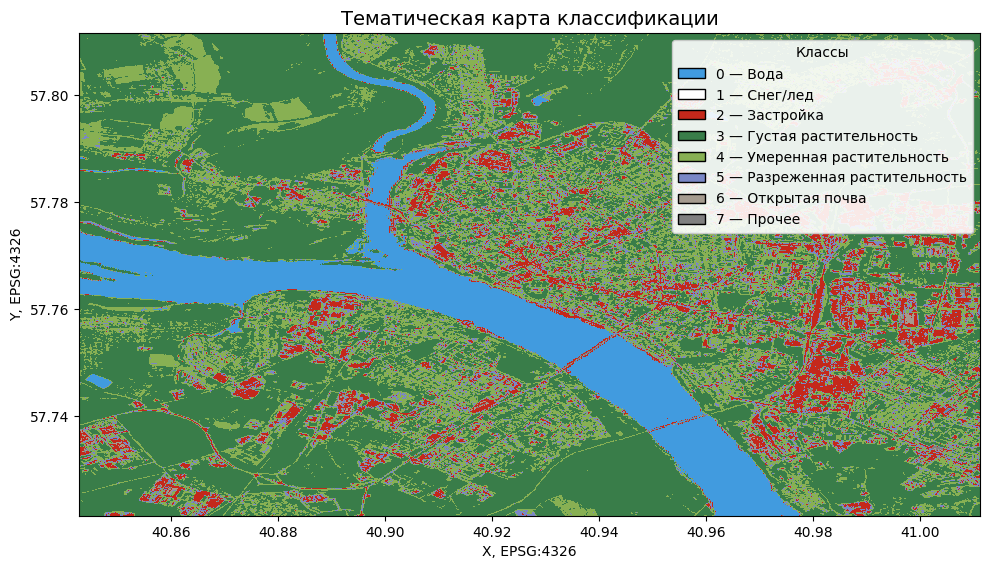

In [ ]:
def draw_segment(data, transform, crs, bounds):
  class_info = {
      0: ('Вода', '#419bdf'),
      1: ('Снег/лед', '#ffffff'),
      2: ('Застройка', '#c4281b'),
      3: ('Густая растительность', '#397d49'),
      4: ('Умеренная растительность', '#88b053'),
      5: ('Разреженная растительность', '#7a87c6'),
      6: ('Открытая почва', '#a59b8f'),
      7: ('Прочее', '#808080')
  }

  codes = sorted(class_info.keys())
  names = [class_info[c][0] for c in codes]
  colors = [class_info[c][1] for c in codes]

  max_code = max(codes)
  palette = ["#ffffff"] * (max_code + 1)
  for c, col in zip(codes, colors):
      palette[c] = col

  cmap = ListedColormap(palette)
  norm = BoundaryNorm(np.arange(-0.5, max_code + 1.5, 1), cmap.N)

  fig, ax = plt.subplots(figsize=(10, 10))

  extent = (bounds.left, bounds.right, bounds.bottom, bounds.top)

  im = ax.imshow(
      data,
      cmap=cmap,
      norm=norm,
      extent=extent,
      interpolation="nearest",
  )

  ax.set_title("Тематическая карта классификации", fontsize=14)
  ax.set_xlabel(f"X, {crs}")
  ax.set_ylabel(f"Y, {crs}")

  legend_elements = [
      Patch(facecolor=class_info[c][1], edgecolor="black", label=f"{c} — {class_info[c][0]}")
      for c in codes
  ]
  ax.legend(
      handles=legend_elements,
      loc="upper right",
      title="Классы",
      framealpha=0.9,
  )

  plt.tight_layout()
  plt.savefig("classification_map.png", dpi=200, bbox_inches="tight")
  plt.show()

with rasterio.open('/content/2024/segmentation_2024.tif') as src:
  draw_segment(src.read(1), src.transform, src.crs, src.bounds)

## **6. Анализ динамики изменений на сегментированных растрах**

### **6.1. Рассчитать площади всех классов для каждого года**



**Формула перевода пикселей в площадь:**
```
Площадь (га) = Количество_пикселей × (Разрешение_м)² / 10000
Площадь (км²) = Количество_пикселей × (Разрешение_м)² / 1000000
```
Для Sentinel-2: разрешение = 10 м, следовательно:
- 1 пиксель = 100 м² = 0.01 га
- 100 пикселей = 1 га
- 10000 пикселей = 1 км²

In [ ]:
class_names = {
    0: 'Вода', 1: 'Снег/лед', 2: 'Застройка',
    3: 'Густая растительность', 4: 'Умеренная растительность',
    5: 'Разреженная растительность', 6: 'Открытая почва', 7: 'Прочее',
}
square_dict = {'Class': [], 2019: [], 2020: [], 2021: [], 2022: [], 2023: [], 2024: []}
resolution = 10
for key, value in table_dict.items():
  for i in value:
    if key == 'Class':
      square_dict[key].append(class_names[i])
    else:
      square_dict[key].append(int(i) * resolution ** 2 / 10000)

square_df = pd.DataFrame(square_dict).drop('Class', axis=1).rename(class_names)
display(square_df)

,2019,2020,2021,2022,2023,2024
Вода,1840.74,1770.87,1745.02,1751.49,1665.53,1769.24
Снег/лед,0.00,0.00,0.00,0.00,0.00,0.00
Застройка,1302.04,1493.36,1619.70,1534.62,1529.48,1405.92
Густая растительность,10092.93,9788.98,9388.90,9180.79,9411.67,9651.06
Умеренная растительность,4185.44,4323.95,4542.42,4725.89,4485.56,4476.96
Разреженная растительность,1312.09,1318.08,1412.94,1484.32,1581.23,1377.89
Открытая почва,48.68,53.86,56.52,72.60,78.36,82.07
Прочее,43.08,75.90,59.50,75.29,73.17,61.86


### **6.2. Построить графики динамики изменений для каждого класса**



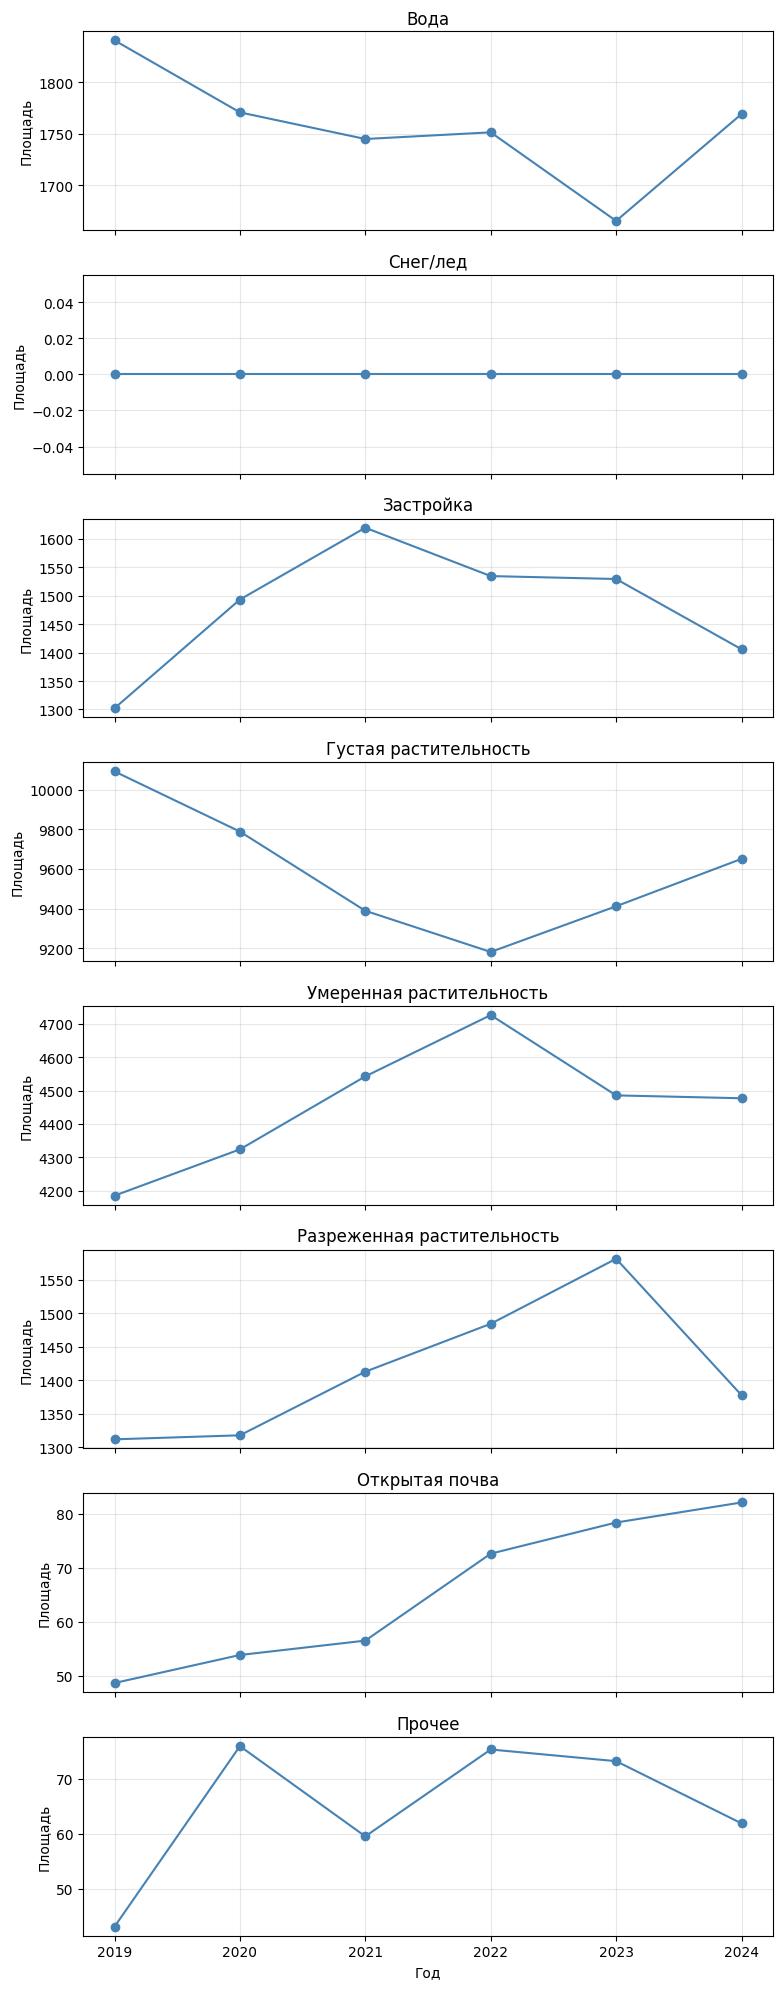

In [ ]:
class_names = {
    0: 'Вода', 1: 'Снег/лед', 2: 'Застройка',
    3: 'Густая растительность', 4: 'Умеренная растительность',
    5: 'Разреженная растительность', 6: 'Открытая почва', 7: 'Прочее',
}

years = [int(k) for k in square_dict if k != 'Class']

fig, axes = plt.subplots(len(square_dict['Class']), 1, figsize=(8, 20), sharex=True)

for ax, cls in zip(axes, square_dict['Class']):
    values = [square_dict[str(y)][cls] for y in years]
    ax.plot(years, values, marker='o', color='steelblue')
    ax.set_title(class_names.get(cls, f'Класс {cls}'))
    ax.set_ylabel('Площадь')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Год')
plt.tight_layout()
plt.show()

### **6.3. Рассчитать все статистические показатели**



**Обязательные метрики для каждого класса:**

1. **Абсолютные показатели:**
   - Площадь в га и км² для каждого года
   - Количество пикселей
   - Процент от общей площади ROI

2. **Показатели изменений:**
   - Абсолютное изменение площади (га): ΔS = S₂₀₂₄ - S₂₀₁₇
   - Относительное изменение (%): (S₂₀₂₄ - S₂₀₁₇) / S₂₀₁₇ × 100%
   - Среднегодовой прирост (га/год): ΔS / количество_лет
   - Среднегодовой темп роста (%/год): ((S₂₀₂₄/S₂₀₁₇)^(1/7) - 1) × 100%

3. **Статистика временного ряда:**
   - Коэффициент вариации: CV = σ/μ × 100% (вспомните материал прошлого семестра, а именно работу в numpy)
   - Стандартное отклонение площадей

In [ ]:
def calculate_statistic(_dict, _years):
  stats = pd.DataFrame(index=_dict.index)
  n_years = _years[-1] - _years[0]
  stats[f'S_{_years[0]}, га'] = _dict[_years[0]]
  stats[f'S_{_years[-1]}, га'] = _dict[_years[-1]]
  stats['ΔS, га'] = stats[f'S_{_years[-1]}, га'] - stats[f'S_{_years[0]}, га']
  stats['ΔS, %'] = 100 * stats['ΔS, га'] / stats[f'S_{_years[0]}, га']
  stats['Среднегодовой прирост, га/год'] = stats['ΔS, га'] / n_years
  stats['Среднегодовой темп, %/год'] = 100 * ((stats[f'S_{_years[-1]}, га'] / stats[f'S_{_years[0]}, га']) ** (1 / n_years) - 1)
  stats['Средняя площадь μ, га'] = list(pd.DataFrame(_dict).iloc[:, 1:].mean(axis=1))
  stats['Стандартное отклонение σ, га'] = list(pd.DataFrame(_dict).iloc[:, 1:].std(axis=1, ddof=0))
  stats['CV, %'] = 100 * stats['Стандартное отклонение σ, га'] / stats['Средняя площадь μ, га']
  return stats

statistic = calculate_statistic(square_df, years)
display(statistic.round(2))

,"S_2019, га","S_2024, га","ΔS, га","ΔS, %","Среднегодовой прирост, га/год","Среднегодовой темп, %/год","Средняя площадь μ, га","Стандартное отклонение σ, га","CV, %"
Вода,1840.74,1769.24,-71.50,-3.88,-14.30,-0.79,1740.43,38.76,2.23
Снег/лед,0.00,0.00,0.00,NaN,0.00,NaN,0.00,0.00,NaN
Застройка,1302.04,1405.92,103.88,7.98,20.78,1.55,1516.62,69.15,4.56
Густая растительность,10092.93,9651.06,-441.87,-4.38,-88.37,-0.89,9484.28,213.14,2.25
Умеренная растительность,4185.44,4476.96,291.52,6.97,58.30,1.36,4510.96,129.58,2.87
Разреженная растительность,1312.09,1377.89,65.80,5.01,13.16,0.98,1434.89,90.81,6.33
Открытая почва,48.68,82.07,33.39,68.59,6.68,11.01,68.68,11.45,16.68
Прочее,43.08,61.86,18.78,43.59,3.76,7.50,69.14,7.01,10.14


### **6.4. Определить какие классы показали наибольшие изменения**



**Критерии определения значимых изменений:**
- Изменение площади > 10% от начального значения
- Абсолютное изменение > 10 га
- Ранжировать классы по величине относительных изменений

In [ ]:
changes_dict = statistic[(statistic['ΔS, %'].abs() > 10) & (statistic['ΔS, га'].abs() > 10)].copy()
changes_dict['Ранг'] = changes_dict['ΔS, %'].abs().rank(ascending=False).astype(int)
changes_dict = changes_dict.sort_values('Ранг')
display(changes_dict[[f'S_{years[0]}, га', f'S_{years[-1]}, га', 'ΔS, га', 'ΔS, %', 'Ранг']].round(2))

ranking = statistic.reindex(statistic['ΔS, %'].abs().sort_values(ascending=False).index)
print("Ранжирование классов по величине относительных изменений:")
display(ranking[[f'S_{years[0]}, га', f'S_{years[-1]}, га', 'ΔS, га', 'ΔS, %']].round(2))

print("\nНаибольшие изменения:", ranking.index[0],
      f"({ranking['ΔS, %'].iloc[0]:+.2f} %; {ranking['ΔS, га'].iloc[0]:+.2f} га)")

,"S_2019, га","S_2024, га","ΔS, га","ΔS, %",Ранг
Открытая почва,48.68,82.07,33.39,68.59,1
Прочее,43.08,61.86,18.78,43.59,2


Ранжирование классов по величине относительных изменений:


,"S_2019, га","S_2024, га","ΔS, га","ΔS, %"
Открытая почва,48.68,82.07,33.39,68.59
Прочее,43.08,61.86,18.78,43.59
Застройка,1302.04,1405.92,103.88,7.98
Умеренная растительность,4185.44,4476.96,291.52,6.97
Разреженная растительность,1312.09,1377.89,65.80,5.01
Густая растительность,10092.93,9651.06,-441.87,-4.38
Вода,1840.74,1769.24,-71.50,-3.88
Снег/лед,0.00,0.00,0.00,NaN



Наибольшие изменения: Открытая почва (+68.59 %; +33.39 га)


### **6.5. Создать сводную таблицу результатов**



| Класс | S_2017 (га) | S_2024 (га) | ΔS (га) | Δ% | Темп (%/год) | Тренд | CV (%) |
|-------|-------------|-------------|---------|-----|--------------|-------|-----|
| Вода | ... | ... | ... | ... | ... | ↑/↓/→ | ... |
| Растительность | ... | ... | ... | ... | ... | ↑/↓/→ | ... |
| ... | ... | ... | ... | ... | ... | ... | ... |

In [ ]:
def detect_trend(value):
  if pd.isna(value):
    return '—'
  if value > 1:
    return '↑'
  if value < -1:
    return '↓'
  return '→'

def make_table(stats, _years):
  return pd.DataFrame({
      f'S_{_years[0]} (га)': stats[f'S_{_years[0]}, га'].round(2),
      f'S_{_years[-1]} (га)': stats[f'S_{_years[-1]}, га'].round(2),
      'ΔS (га)': stats['ΔS, га'].round(2),
      'Δ%': stats['ΔS, %'].round(2),
      'Темп (%/год)': stats['Среднегодовой темп, %/год'].round(2),
      'Тренд': stats['ΔS, %'].apply(detect_trend),
      'CV (%)': stats['CV, %'].round(2),
  })

result_table = make_table(statistic, years)
result_table.index.name = 'Класс'
display(result_table)

,S_2019 (га),S_2024 (га),ΔS (га),Δ%,Темп (%/год),Тренд,CV (%)
Класс,,,,,,,
Вода,1840.74,1769.24,-71.50,-3.88,-0.79,↓,2.23
Снег/лед,0.00,0.00,0.00,NaN,NaN,—,NaN
Застройка,1302.04,1405.92,103.88,7.98,1.55,↑,4.56
Густая растительность,10092.93,9651.06,-441.87,-4.38,-0.89,↓,2.25
Умеренная растительность,4185.44,4476.96,291.52,6.97,1.36,↑,2.87
Разреженная растительность,1312.09,1377.89,65.80,5.01,0.98,↑,6.33
Открытая почва,48.68,82.07,33.39,68.59,11.01,↑,16.68
Прочее,43.08,61.86,18.78,43.59,7.50,↑,10.14


## **7. Валидация результатов**

### **7.1. Рассчитать площади всех классов для каждого года по картам классификации**



In [ ]:
def get_pixel(src):
  res_x, res_y = abs(src.res[0]), abs(src.res[1])
  if src.crs is not None and src.crs.is_geographic:
    lat = (src.bounds.top + src.bounds.bottom) / 2
    m_per_deg_lat = 111320
    m_per_deg_lon = 111320 * np.cos(np.radians(lat))
    return (res_x * m_per_deg_lon) * (res_y * m_per_deg_lat)
  return res_x * res_y

def read_labels(src):
  data = src.read(1)
  labels = np.full(data.shape, -1, dtype=np.int16)
  if np.issubdtype(data.dtype, np.floating):
    valid = ~np.isnan(data)
  else:
    valid = np.ones(data.shape, dtype=bool)
  labels[valid] = np.rint(data[valid]).astype(np.int16)
  return labels

def areas_from_labels(labels, names, pixel_area_m2):
  unique_labels, counts = np.unique(labels, return_counts=True)
  areas = pd.Series(0.0, index=list(names.values()))
  for label, count in zip(unique_labels, counts):
    if label == -1:
      continue
    areas[names[int(label)]] = int(count) * pixel_area_m2 / 1e4
  return areas

landcover_maps = {}
for year in years:
  with rasterio.open(f"/content/DYNAMICWORLD_summer_{year}.tif") as src:
    landcover_maps[year] = read_labels(src)
with rasterio.open(f"/content/DYNAMICWORLD_summer_{years[0]}.tif") as src:
  pixel_area_m2_dw = get_pixel(src)
print(f"Площадь пикселя: {pixel_area_m2_dw:.2f} м2")

landcover_areas_ha = pd.DataFrame(
    {year: areas_from_labels(landcover_maps[year], class_names, pixel_area_m2_dw)
     for year in years})
landcover_areas_km2 = landcover_areas_ha / 1e2
landcover_percent = (100 * landcover_areas_ha / landcover_areas_ha.sum()).round(2)
print("Площадь в га:")
display(landcover_areas_ha.round(2))
print("Площадь в км2:")
display(landcover_areas_km2.round(3))
print("Процент от площади ROI:")
display(landcover_percent)

Площадь пикселя: 53.34 м2
Площадь в га:


,2019,2020,2021,2022,2023,2024
Вода,1177.44,1179.01,1138.96,1146.83,1154.14,1127.34
Снег/лед,2843.06,2467.95,2848.13,2811.05,2961.63,3147.80
Застройка,297.82,356.28,299.95,234.25,221.61,263.79
Густая растительность,64.68,89.38,83.14,60.83,55.90,69.50
Умеренная растительность,542.75,787.46,458.51,560.21,483.07,293.08
Разреженная растительность,7.93,5.58,7.13,4.46,3.95,2.50
Открытая почва,5104.73,5151.94,5201.86,5219.40,5157.75,5133.68
Прочее,2.39,3.18,3.11,3.76,2.74,3.10


Площадь в км2:


,2019,2020,2021,2022,2023,2024
Вода,11.774,11.790,11.390,11.468,11.541,11.273
Снег/лед,28.431,24.680,28.481,28.110,29.616,31.478
Застройка,2.978,3.563,2.999,2.342,2.216,2.638
Густая растительность,0.647,0.894,0.831,0.608,0.559,0.695
Умеренная растительность,5.428,7.875,4.585,5.602,4.831,2.931
Разреженная растительность,0.079,0.056,0.071,0.045,0.040,0.025
Открытая почва,51.047,51.519,52.019,52.194,51.578,51.337
Прочее,0.024,0.032,0.031,0.038,0.027,0.031


Процент от площади ROI:


,2019,2020,2021,2022,2023,2024
Вода,11.73,11.74,11.34,11.42,11.49,11.23
Снег/лед,28.32,24.58,28.37,28.00,29.50,31.35
Застройка,2.97,3.55,2.99,2.33,2.21,2.63
Густая растительность,0.64,0.89,0.83,0.61,0.56,0.69
Умеренная растительность,5.41,7.84,4.57,5.58,4.81,2.92
Разреженная растительность,0.08,0.06,0.07,0.04,0.04,0.02
Открытая почва,50.84,51.31,51.81,51.98,51.37,51.13
Прочее,0.02,0.03,0.03,0.04,0.03,0.03


### **7.2. Построить графики динамики изменений для каждого класса по картам классификации**



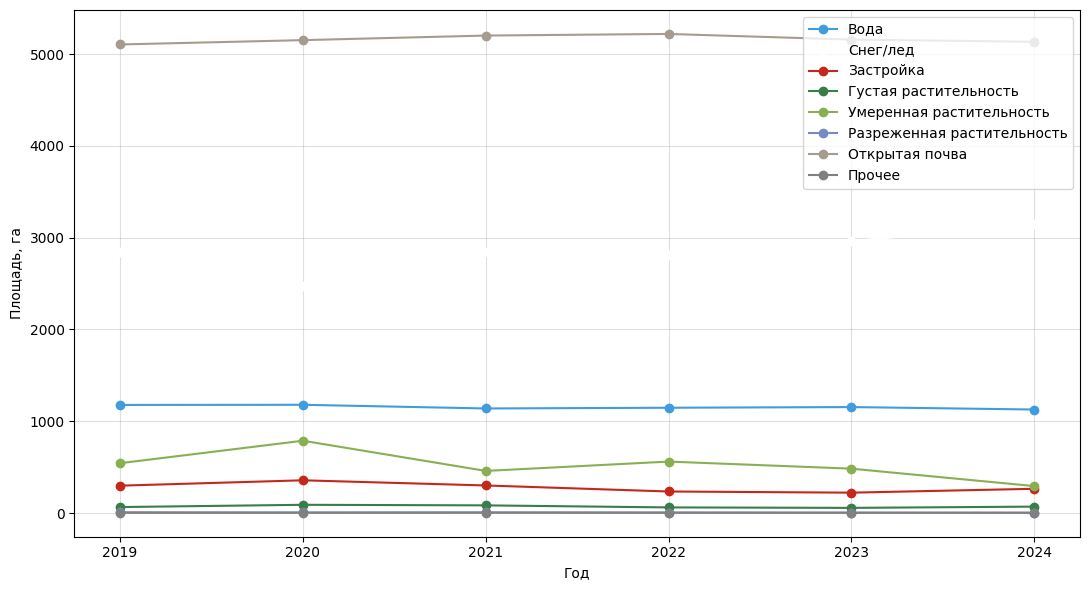

In [ ]:
class_colors = ['#419bdf', '#ffffff', '#c4281b', '#397d49',
                '#88b053', '#7a87c6', '#a59b8f', '#808080']

plt.figure(figsize=(11, 6))
for name, color in zip(class_names.values(), class_colors):
    plt.plot(years, landcover_areas_ha.loc[name].values, marker='o', label=name, color=color)
plt.xlabel('Год')
plt.ylabel('Площадь, га')
plt.xticks(years)
plt.grid(True, alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

### **7.3. Рассчитать все статистические показатели по картам классификации**



In [ ]:
landcover_stats = calculate_statistic(landcover_areas_ha, years)
display(landcover_stats.round(2))

,"S_2019, га","S_2024, га","ΔS, га","ΔS, %","Среднегодовой прирост, га/год","Среднегодовой темп, %/год","Средняя площадь μ, га","Стандартное отклонение σ, га","CV, %"
Вода,1177.44,1127.34,-50.09,-4.25,-10.02,-0.87,1149.26,17.33,1.51
Снег/лед,2843.06,3147.80,304.74,10.72,60.95,2.06,2847.31,222.98,7.83
Застройка,297.82,263.79,-34.03,-11.43,-6.81,-2.40,275.17,48.72,17.70
Густая растительность,64.68,69.50,4.82,7.45,0.96,1.45,71.75,12.78,17.81
Умеренная растительность,542.75,293.08,-249.67,-46.00,-49.93,-11.59,516.47,161.07,31.19
Разреженная растительность,7.93,2.50,-5.43,-68.51,-1.09,-20.63,4.72,1.56,32.97
Открытая почва,5104.73,5133.68,28.95,0.57,5.79,0.11,5172.93,32.28,0.62
Прочее,2.39,3.10,0.71,29.62,0.14,5.33,3.18,0.33,10.33


### **7.4. Определить какие классы показали наибольшие изменения по картам классификации**



In [ ]:
landcover_changes = landcover_stats[(landcover_stats['ΔS, %'].abs() > 10) & (landcover_stats['ΔS, га'].abs() > 10)].copy()

if landcover_changes.empty:
    print()
else:
    landcover_changes['Ранг'] = (landcover_changes['ΔS, %'].abs().rank(ascending=False).astype(int))
    landcover_changes = landcover_changes.sort_values('Ранг')
    display(landcover_changes[[f'S_{years[0]}, га', f'S_{years[-1]}, га', 'ΔS, га', 'ΔS, %', 'Ранг']].round(2))
landcover_ranking = landcover_stats.reindex(landcover_stats['ΔS, %'].abs().sort_values(ascending=False).index)
print("Ранжирование классов по величине изменений:")
display(landcover_ranking[[f'S_{years[0]}, га', f'S_{years[-1]}, га', 'ΔS, га', 'ΔS, %']].round(2))
print("\nНаибольшие изменения:", landcover_ranking.index[0],
      f"({landcover_ranking['ΔS, %'].iloc[0]} %; "
      f"{landcover_ranking['ΔS, га'].iloc[0]} га)")

,"S_2019, га","S_2024, га","ΔS, га","ΔS, %",Ранг
Умеренная растительность,542.75,293.08,-249.67,-46.00,1
Застройка,297.82,263.79,-34.03,-11.43,2
Снег/лед,2843.06,3147.80,304.74,10.72,3


Ранжирование классов по величине изменений:


,"S_2019, га","S_2024, га","ΔS, га","ΔS, %"
Разреженная растительность,7.93,2.50,-5.43,-68.51
Умеренная растительность,542.75,293.08,-249.67,-46.00
Прочее,2.39,3.10,0.71,29.62
Застройка,297.82,263.79,-34.03,-11.43
Снег/лед,2843.06,3147.80,304.74,10.72
Густая растительность,64.68,69.50,4.82,7.45
Вода,1177.44,1127.34,-50.09,-4.25
Открытая почва,5104.73,5133.68,28.95,0.57



Наибольшие изменения: Разреженная растительность (-68.50605652759084 %; -5.429762302704723 га)


### **7.5. Создать сводную таблицу результатов по картам классификации**



In [ ]:
landcover_table = make_table(landcover_stats, years)
landcover_table.index.name = 'Класс'
display(landcover_table)

,S_2019 (га),S_2024 (га),ΔS (га),Δ%,Темп (%/год),Тренд,CV (%)
Класс,,,,,,,
Вода,1177.44,1127.34,-50.09,-4.25,-0.87,↓,1.51
Снег/лед,2843.06,3147.80,304.74,10.72,2.06,↑,7.83
Застройка,297.82,263.79,-34.03,-11.43,-2.40,↓,17.70
Густая растительность,64.68,69.50,4.82,7.45,1.45,↑,17.81
Умеренная растительность,542.75,293.08,-249.67,-46.00,-11.59,↓,31.19
Разреженная растительность,7.93,2.50,-5.43,-68.51,-20.63,↓,32.97
Открытая почва,5104.73,5133.68,28.95,0.57,0.11,→,0.62
Прочее,2.39,3.10,0.71,29.62,5.33,↑,10.33


## **8. Сравнение результатов полученных по результатам сегментации и картам классификаций**

,2019,2020,2021,2022,2023,2024
Вода,1177.44,1179.01,1138.96,1146.83,1154.14,1127.34
Снег/лед,0.00,0.00,0.00,0.00,0.00,0.00
Застройка,5104.73,5151.94,5201.86,5219.40,5157.75,5133.68
Густая растительность,2843.06,2467.95,2848.13,2811.05,2961.63,3147.80
Умеренная растительность,550.68,793.04,465.64,564.68,487.03,295.58
Разреженная растительность,297.82,356.28,299.95,234.25,221.61,263.79
Открытая почва,2.39,3.18,3.11,3.76,2.74,3.10
Прочее,64.68,89.38,83.14,60.83,55.90,69.50


,"Совпадение с Dynamic World, %"
2019,44.87
2020,42.60
2021,46.83
2022,46.83
2023,46.36
2024,48.03


Среднее совпадение классов за период: 45.92 %
Сравнительная таблица двух методов:


,"Сегментация 2019, га","Dynamic World 2019, га","Сегментация 2024, га","Dynamic World 2024, га",Δ% сегментация,Δ% Dynamic World,"Темп сегм., %/год","Темп DW, %/год","Расхождение, %",Корреляция рядов
Класс,,,,,,,,,,
Вода,1840.74,1177.44,1769.24,1127.34,-3.88,-4.25,-0.79,-0.87,56.94,0.37
Снег/лед,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN
Застройка,1302.04,5104.73,1405.92,5133.68,7.98,0.57,1.55,0.11,-72.61,0.87
Густая растительность,10092.93,2843.06,9651.06,3147.80,-4.38,10.72,-0.89,2.06,206.60,-0.18
Умеренная растительность,4185.44,550.68,4476.96,295.58,6.97,-46.32,1.36,-11.70,1414.63,-0.28
Разреженная растительность,1312.09,297.82,1377.89,263.79,5.01,-11.43,0.98,-2.40,422.35,-0.84
Открытая почва,48.68,2.39,82.07,3.10,68.59,29.62,11.01,5.33,2543.80,0.34
Прочее,43.08,64.68,61.86,69.50,43.59,7.45,7.50,1.45,-10.99,0.06


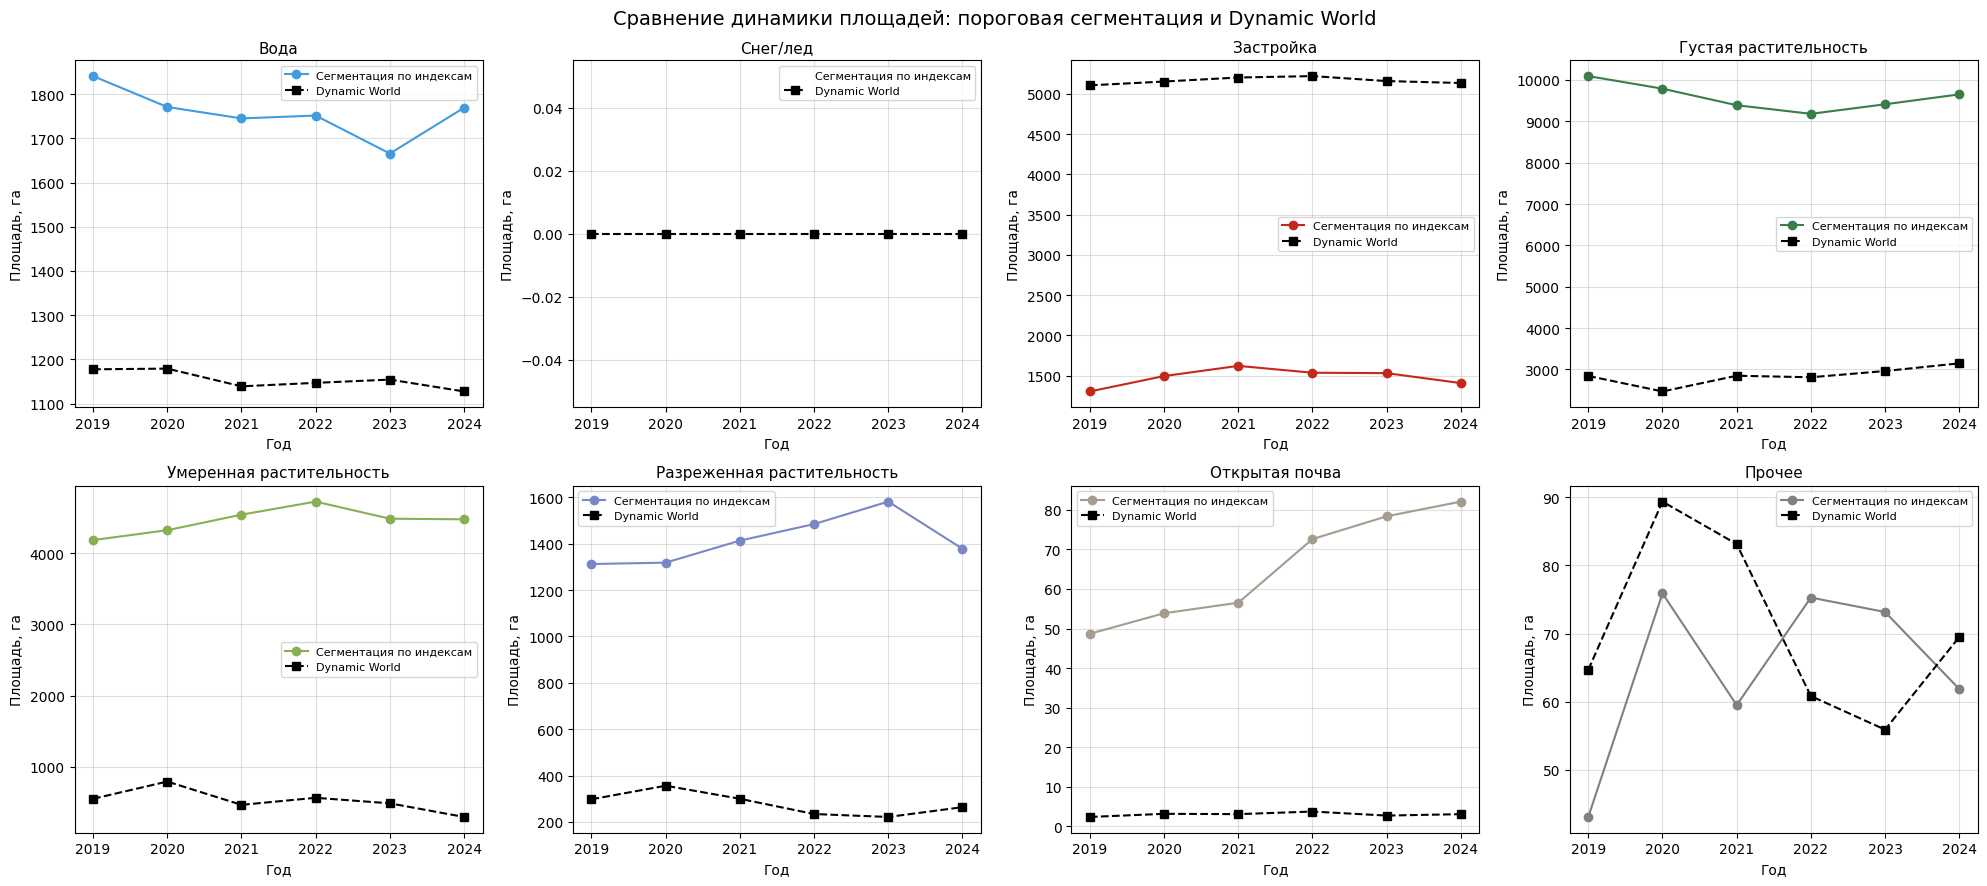

Матрица соответствия классов (число пикселей), 2024:


,Вода,Снег/лед,Застройка,Густая растительность,Умеренная растительность,Разреженная растительность,Открытая почва,Прочее
Сегментация \ Dynamic World,,,,,,,,
Вода,175398,0,155,23,0,0,0,1348
Снег/лед,0,0,0,0,0,0,0,0
Застройка,5008,0,133906,563,582,29,483,21
Густая растительность,12324,0,311428,562377,20629,48184,0,10164
Умеренная растительность,11263,0,376859,24712,32419,1183,8,1252
Разреженная растительность,5064,0,128085,2487,1787,60,77,229
Открытая почва,424,0,7761,2,0,0,14,6
Прочее,1879,0,4295,2,0,0,0,10


In [ ]:
dw_to_seg = {0: 0, 1: 3, 2: 5, 3: 7, 4: 4, 5: 4, 6: 2, 7: 6, 8: 1}
dw_lut = np.array([dw_to_seg[label] for label in range(9)], dtype=np.int16)
mapped_dw = {}
for year in years:
    mapped = landcover_maps[year].copy()
    valid = mapped != -1
    mapped[valid] = dw_lut[mapped[valid].clip(0, 8)]
    mapped_dw[year] = mapped
landcover_areas_mapped_ha = pd.DataFrame({year: areas_from_labels(mapped_dw[year], class_names, pixel_area_m2_dw) for year in years})
landcover_mapped_stats = calculate_statistic(landcover_areas_mapped_ha, years)
display(landcover_areas_mapped_ha.round(2))
agreement = {}
for year in years:
    valid = (segmented[year] != -1) & (mapped_dw[year] != -1)
    agreement[year] = round(100 * float(np.mean(segmented[year][valid] == mapped_dw[year][valid])), 2)

agreement_series = pd.Series(agreement, name='Совпадение с Dynamic World, %')
display(agreement_series)
print(f"Среднее совпадение классов за период: {agreement_series.mean():.2f} %")
def series_correlation(a, b):
    if a.std(ddof=0) == 0 or b.std(ddof=0) == 0:
        return np.nan
    return float(np.corrcoef(a.values, b.values)[0, 1])
with np.errstate(divide='ignore', invalid='ignore'):
    correlation = pd.Series({name: series_correlation(square_df.loc[name], landcover_areas_mapped_ha.loc[name])
         for name in class_names.values()})

comparison = pd.DataFrame({
    f'Сегментация {years[0]}, га': square_df[years[0]],
    f'Dynamic World {years[0]}, га': landcover_areas_mapped_ha[years[0]],
    f'Сегментация {years[-1]}, га': square_df[years[-1]],
    f'Dynamic World {years[-1]}, га': landcover_areas_mapped_ha[years[-1]],
    'Δ% сегментация': statistic['ΔS, %'],
    'Δ% Dynamic World': landcover_mapped_stats['ΔS, %'],
    'Темп сегм., %/год': statistic['Среднегодовой темп, %/год'],
    'Темп DW, %/год': landcover_mapped_stats['Среднегодовой темп, %/год'],
    'Расхождение, %': 100 * (square_df[years[-1]] - landcover_areas_mapped_ha[years[-1]])
                      / landcover_areas_mapped_ha[years[-1]],
    'Корреляция рядов': correlation,
})
comparison = comparison.round(2)
comparison.index.name = 'Класс'
print("Сравнительная таблица двух методов:")
display(comparison)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 9))
for ax, (name, color) in zip(axes.flatten(), zip(class_names.values(), class_colors)):
    ax.plot(years, square_df.loc[name].values, marker='o', color=color, label='Сегментация по индексам')
    ax.plot(years, landcover_areas_mapped_ha.loc[name].values, marker='s', ls='--', color='black', label='Dynamic World')
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('Год')
    ax.set_ylabel('Площадь, га')
    ax.set_xticks(years)
    ax.grid(True, alpha=0.4)
    ax.legend(fontsize=8)
plt.suptitle('Сравнение динамики площадей: пороговая сегментация и Dynamic World', fontsize=14)
plt.tight_layout()
plt.show()

valid = (segmented[2024] != -1) & (mapped_dw[2024] != -1)
confusion = np.bincount(segmented[2024][valid].astype(np.int64) * 8 + mapped_dw[2024][valid], minlength=64).reshape(8, 8)
confusion_df = pd.DataFrame(confusion, index=list(class_names.values()), columns=list(class_names.values()))
confusion_df.index.name = 'Сегментация \\ Dynamic World'
print("Матрица соответствия классов (число пикселей), 2024:")
display(confusion_df)

## **9. Выводы**

В выводах обязательно отразить:
1. **Количественная оценка динамики** (с конкретными цифрами для каждого класса)
2. **Выявленные тренды** (растущие, убывающие, стабильные классы)
3. **Скорость изменений** (га/год и %/год для ключевых классов)
4. **Пространственные закономерности** (где происходят основные изменения)
5. **Точность методов** (сравнение с эталоном в %)

1. Количественная оценка динамики
2. Выявленные тренды
- Растущие: прочее, открытая почва, густая растительность;
- Убывающие: вода, умеренная растительность, разреженная растительность;
- Стабильные: застройка, снег/лёд.
3. Скорость изменений (сегм. / DW):
- Вода: -0.79 / -0.87;
- Застройка: 1.55 /	0.11;
- Густая растительность: -0.89 / 2.06;
- Умеренная растительность: 1.36 / -11.70;
- Разреженная растительность: 0.98 / -2.40;
- Открытая почва: 11.01	/ 5.33;
- Прочее: 7.50 / 1.45.
4. Пространственные закономерности: основные изменения происходят в классах "Застройка" и "Растительность"
5. Точность методов: 45.92%